<center><img src="https://i.imgur.com/zRrFdsf.png" width="700"></center>





<a target="_blank" href="https://colab.research.google.com/github/CienciaDeDatosEspacial/spatial_autoCorr/blob/main/index.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


# Neighboorhood and Spatial Correlation.



## Getting ready


### Libraries needed

Let's verify:

In [2]:
!pip show pysal pandas geopandas

Name: pysal
Version: 25.7
Summary: Meta Package for PySAL - A library of spatial analysis functions
Home-page: 
Author: 
Author-email: Serge Rey <sjsrey@gmail.com>, Levi Wolf <levi.john.wolf@gmail.com>
License: BSD 3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: access, beautifulsoup4, esda, geopandas, giddy, inequality, libpysal, mapclassify, mgwr, momepy, numpy, packaging, pandas, platformdirs, pointpats, requests, scikit-learn, scipy, segregation, shapely, spaghetti, spglm, spint, splot, spopt, spreg, tobler
Required-by: 
---
Name: pandas
Version: 2.2.3
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
All rights reserved.

Copyright (c) 2011-2023, Open source contributors.

Redistribution 

In [3]:
## needed in Colab
!pip install pysal

### Data to use



1. A map of Peru, at the **'distrito'** level. The map comes from an unoffical [website](https://www.geogpsperu.com/p/descargas.html). Some columns with **social data** have been added. This will be used at the end of this material.

In [1]:
import geopandas as gpd
peruDataLink="https://github.com/rodrigosalazarl-GH/LISA_PERU/raw/main/data/PeruMaps.gpkg"
peru_distritos=gpd.read_file(peruDataLink,layer='distritos')

# some basic info
peru_distritos.info(),peru_distritos.crs.to_epsg(),peru_distritos.crs.is_projected

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1874 entries, 0 to 1873
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   DEPARTAMEN                1874 non-null   object  
 1   PROVINCIA                 1874 non-null   object  
 2   DISTRITO                  1874 non-null   object  
 3   Ubigeo                    1874 non-null   object  
 4   Poblacion                 1874 non-null   int64   
 5   Superficie                1874 non-null   float64 
 6   IDH2019                   1874 non-null   float64 
 7   Educ_sec_comp2019_pct     1874 non-null   float64 
 8   NBI2017_pct               1874 non-null   float64 
 9   Viv_sin_serv_hig2017_pct  1874 non-null   float64 
 10  geometry                  1874 non-null   geometry
dtypes: float64(5), geometry(1), int64(1), object(4)
memory usage: 161.2+ KB


(None, 4326, False)

Let's reproject and plot:

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

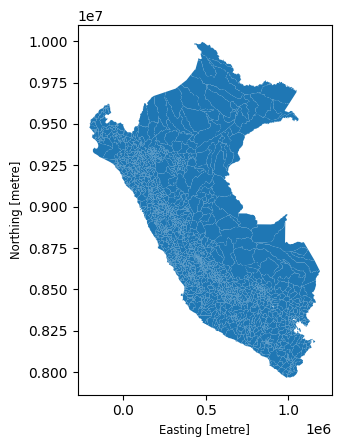

In [4]:
peru_distritos=peru_distritos.to_crs(32718)
peru_distritos.plot()

Besides the spatial units (DEPARTAMEN, PROVINCIA, DISTRITO, and Ubigeo - "Ubigeo" is a code ), you have:
 - **Poblacion**: Population (2017)
 - **Superficie**: Area               
 - **IDH2019**: Human Development Index for DISTRITO (2019)                   
 - **Educ_sec_comp2019_pct**: Share of Population that finished High-School (2019)     
 - **NBI2017_pct**: Share of Population with poverty at the household level aggregated by DISTRITO. This index ("Unsatisfied Basic Needs") uses observable living conditions rather than income alone (2017).
 - **Viv_sin_serv_hig2017_pct**: Share of housing units that have no sanitation infrastructure aggregated by  DISTRITO (2017)

The last two sections (III and IV) will need these **social data**.


Notice we should not use the 'distrito' name as index, because several of them are repeated:

In [5]:
peru_distritos[peru_distritos['DISTRITO'].duplicated()]

,DEPARTAMEN,PROVINCIA,DISTRITO,Ubigeo,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
191,PUNO,LAMPA,PALCA,210706,2871,483.96,0.465326,68.506619,61.6,14.3,"MULTIPOLYGON (((980731.13 8315234.38, 980743.3..."
214,AYACUCHO,PAUCAR DEL SARA SARA,LAMPA,050804,2590,289.45,0.395363,60.608667,31.3,15.4,"MULTIPOLYGON (((666120.18 8335108.23, 666139.9..."
256,AYACUCHO,LUCANAS,SANTA LUCIA,050621,889,1019.14,0.442814,58.278405,64.7,47.6,"MULTIPOLYGON (((565436.58 8372074.78, 565495.3..."
259,AYACUCHO,LUCANAS,SAN CRISTOBAL,050615,2182,391.83,0.236161,68.230879,31.5,13.7,"MULTIPOLYGON (((576905.62 8374974.87, 577009.7..."
272,CUSCO,ESPINAR,COPORAQUE,080803,18004,1564.46,0.289550,75.551079,26.1,8.9,"MULTIPOLYGON (((863229.34 8390956.29, 863465.6..."
...,...,...,...,...,...,...,...,...,...,...,...
1844,LIMA,LIMA,LA VICTORIA,150115,169270,8.74,0.714159,74.791799,15.3,0.0,"MULTIPOLYGON (((280479.644 8666127.227, 280593..."
1845,LIMA,LIMA,SAN LUIS,150134,59377,3.49,0.793258,80.699041,9.4,0.0,"MULTIPOLYGON (((282530.051 8665926.351, 282499..."
1847,LIMA,LIMA,SAN MIGUEL,150136,139399,10.72,0.822401,76.664090,4.5,0.0,"MULTIPOLYGON (((273775.884 8664656.624, 273772..."
1855,LIMA,LIMA,SAN ISIDRO,150131,54298,11.10,0.788832,78.470219,1.1,0.0,"MULTIPOLYGON (((277019.308 8663207.821, 277130..."


Let's use 'Ubigeo', although it is not the best solution. Esto identifica los distritos, sin el riesgo de que se repita el nombre.

In [6]:
# of course
peru_distritos[peru_distritos['Ubigeo'].duplicated()]

,DEPARTAMEN,PROVINCIA,DISTRITO,Ubigeo,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry


In [7]:
#then
peru_distritos.set_index('Ubigeo', inplace=True)

In [8]:
departamentos = ['ANCASH', 'HUANUCO','LA LIBERTAD']

peru_selected = peru_distritos[
    peru_distritos['DEPARTAMEN'].isin(departamentos)
].copy()

In [9]:
peru_selected['DEPARTAMEN'].value_counts()

,count
DEPARTAMEN,
ANCASH,166
HUANUCO,84
LA LIBERTAD,83


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

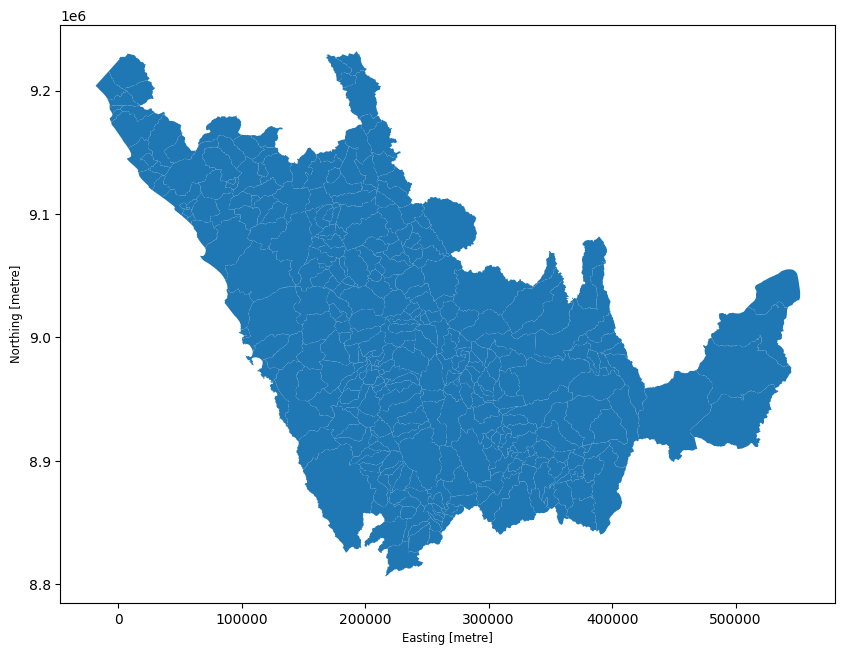

In [10]:
peru_selected.plot(figsize=(10, 10))

In [11]:
peru_selected.crs

<Projected CRS: EPSG:32718>
Name: WGS 84 / UTM zone 18S
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 78°W and 72°W, southern hemisphere between 80°S and equator, onshore and offshore. Argentina. Brazil. Chile. Colombia. Ecuador. Peru.
- bounds: (-78.0, -80.0, -72.0, 0.0)
Coordinate Operation:
- name: UTM zone 18S
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [12]:
peru_selected.crs.is_projected

True

## I. Who is my neighbor?

In spatial analysis, the intuitive concept of a “neighbor” can be operationalized in multiple ways.

So far, we have identified neighbors using geometric operations such as buffering, spatial joins, and overlays.

In this session, let’s remember the distance matrix:


In [13]:
from libpysal.graph import Graph

# also for reproducibility!
from numpy.random import seed
seed(40)

### I.1 Binary Contiguity

Take a look at the **queen** and **rook** relationship:

<center><img src="https://github.com/CienciaDeDatosEspacial/spatial_autoCorr/raw/main/rookQueen.png" width="700"></center>

From the image above:
- Your **rook** neighbor is whichever  shares a border with you (a borderline of at least two points). It is also known as the _Von Neumann_ neighbor.

- Your **queen** neighbor is whichever  shares a border or a corner with you (at least one point).It is also known as the _Moore_ neighbor.

Let's see how to get each set of neighbors

#### I.1.A. Rook

* The key idea: A focal polygon considers another polygon a neighbor if they share a common edge—that is, two or more connected points forming a line segment of positive length.
* The input: A GeoDataFrame (GDF) containing polygon geometries (e.g., states, counties, census tracts). Each row represents a spatial unit that can serve as a focal observation.
* The process: For each polygon (focal unit), the algorithm checks all other polygons to determine whether their boundaries intersect along a line segment (not just at a point).
* The output: A graph built from a binary adjacency matrix where each node represents a polygon (focal unit). An edge exists between two nodes only if they share a boundary segment. The corresponding adjacency matrix is binary. Isolates are possible.

Let's use **peru_selected** GDF:

In [14]:
rook=Graph.build_contiguity(peru_selected, rook=True) # rook by default

In [15]:
rook=rook.transform("r")

In [16]:
peru_selected[['DEPARTAMEN', 'DISTRITO']]

,DEPARTAMEN,DISTRITO
Ubigeo,,
021405,ANCASH,COCHAS
021404,ANCASH,CARHUAPAMPA
021402,ANCASH,ACAS
021410,ANCASH,SANTIAGO DE CHILCAS
021408,ANCASH,SAN CRISTOBAL DE RAJAN
...,...,...
100705,HUANUCO,SANTA ROSA DE ALTO YANAJANCA
100608,HUANUCO,CASTILLO GRANDE
100607,HUANUCO,PUCAYACU


Now let's check the ouput:

**a. adjacency**

In [17]:
rook.adjacency

focal   neighbor
021405  021402      0.250000
        021410      0.250000
        021409      0.250000
        021401      0.250000
021404  021402      0.333333
                      ...   
100609  100604      0.166667
        100608      0.166667
        100610      0.166667
100610  100604      0.500000
        100609      0.500000
Name: weight, Length: 1766, dtype: float64

In [18]:
import pandas as pd

rook_matrix = pd.DataFrame(
    rook.adjacency,
    index=peru_selected.index,
    columns=peru_selected.index
)

We generally fill those missing values (not a neighbor) with zero.

In [19]:
rook_matrix = pd.DataFrame(rook.adjacency).unstack().fillna(0)

In [20]:
rook_matrix

weight                                                           \
neighbor 021405    021404    021402    021410    021408 021409    021407   
focal                                                                      
021405     0.00  0.000000  0.250000  0.250000  0.000000   0.25  0.000000   
021404     0.00  0.000000  0.333333  0.000000  0.333333   0.00  0.000000   
021402     0.25  0.250000  0.000000  0.250000  0.250000   0.00  0.000000   
021410     0.25  0.000000  0.250000  0.000000  0.250000   0.00  0.000000   
021408     0.00  0.166667  0.166667  0.166667  0.000000   0.00  0.166667   
...         ...       ...       ...       ...       ...    ...       ...   
100705     0.00  0.000000  0.000000  0.000000  0.000000   0.00  0.000000   
100608     0.00  0.000000  0.000000  0.000000  0.000000   0.00  0.000000   
100607     0.00  0.000000  0.000000  0.000000  0.000000   0.00  0.000000   
100609     0.00  0.000000  0.000000  0.000000  0.000000   0.00  0.000000   
100610     0.00  0.000000  0.000000  0.000000  0.000000   0.00  0.000000   

                               ...                                            \
neighbor 020506 020502 021406  ... 130304 130402 130305 100704 100113 100705   
focal                          ...                                             
021405      0.0    0.0    0.0  ...    0.0    0.0    0.0   0.00    0.0    0.0   
021404      0.0    0.0    0.0  ...    0.0    0.0    0.0   0.00    0.0    0.0   
021402      0.0    0.0    0.0  ...    0.0    0.0    0.0   0.00    0.0    0.0   
021410      0.0    0.0    0.0  ...    0.0    0.0    0.0   0.00    0.0    0.0   
021408      0.0    0.0    0.0  ...    0.0    0.0    0.0   0.00    0.0    0.0   
...         ...    ...    ...  ...    ...    ...    ...    ...    ...    ...   
100705      0.0    0.0    0.0  ...    0.0    0.0    0.0   0.25    0.0    0.0   
100608      0.0    0.0    0.0  ...    0.0    0.0    0.0   0.00    0.0    0.0   
100607      0.0    0.0    0.0  ...    0.0    0.0    0.0   0.00    0.0    0.0   
100609      0.0    0.0    0.0  ...    0.0    0.0    0.0   0.00    0.0    0.0   
100610      0.0    0.0    0.0  ...    0.0    0.0    0.0   0.00    0.0    0.0   

                                               
neighbor    100608 100607    100609    100610  
focal                                          
021405    0.000000    0.0  0.000000  0.000000  
021404    0.000000    0.0  0.000000  0.000000  
021402    0.000000    0.0  0.000000  0.000000  
021410    0.000000    0.0  0.000000  0.000000  
021408    0.000000    0.0  0.000000  0.000000  
...            ...    ...       ...       ...  
100705    0.000000    0.0  0.000000  0.000000  
100608    0.000000    0.0  0.333333  0.000000  
100607    0.000000    0.0  0.000000  0.000000  
100609    0.166667    0.0  0.000000  0.166667  
100610    0.000000    0.0  0.500000  0.000000  

[333 rows x 333 columns]

Para conocer la cantidad de vecinos aislados:

In [21]:
rook.isolates

Index([], dtype='object', name='focal')

In [22]:
len(rook.isolates)

0

SInce we are going to use several times, we may create a custom procedure (Funcion para calcular cualquier matriz de adyacencia):

In [23]:
#instead of
# pd.DataFrame(rook.adjacency).unstack().fillna(0)
toWideMatrix=lambda g:pd.DataFrame(g.adjacency).unstack().fillna(0)

Notice we created this wide matrix for pedagogical purposes. It is a bad idea if you have many columns and rows.

Ahora calculo los indicadores LISA para cada distrito:

In [24]:
import esda

lisa_rook = esda.Moran_Local(
    peru_selected['Educ_sec_comp2019_pct'],
    rook
)

Asignación y calculo de la cantidad de distritos en cada categoría:

In [25]:
peru_selected['HS_lisa_rook'] = lisa_rook.get_cluster_labels(crit_value=0.05)

In [26]:
peru_selected['HS_lisa_rook'].value_counts()

,count
HS_lisa_rook,
Insignificant,234
High-High,56
Low-Low,30
High-Low,9
Low-High,4


In [27]:
oldLabels = ['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High']

newLabels = [
    '3 no_pattern',
    '4 coldSpot',
    '2 hotSpot',
    '1 hotOutlier',
    '5 coldOutlier'
]

labels = dict(zip(oldLabels, newLabels))

peru_selected.replace({'HS_lisa_rook': labels}, inplace=True)

In [28]:
peru_selected['HS_lisa_rook'].value_counts().sort_index()

,count
HS_lisa_rook,
1 hotOutlier,9
2 hotSpot,56
3 no_pattern,234
4 coldSpot,30
5 coldOutlier,4


Mapa:

In [29]:
import matplotlib.pyplot as plt

myColMap = plt.get_cmap('PuOr', 5)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

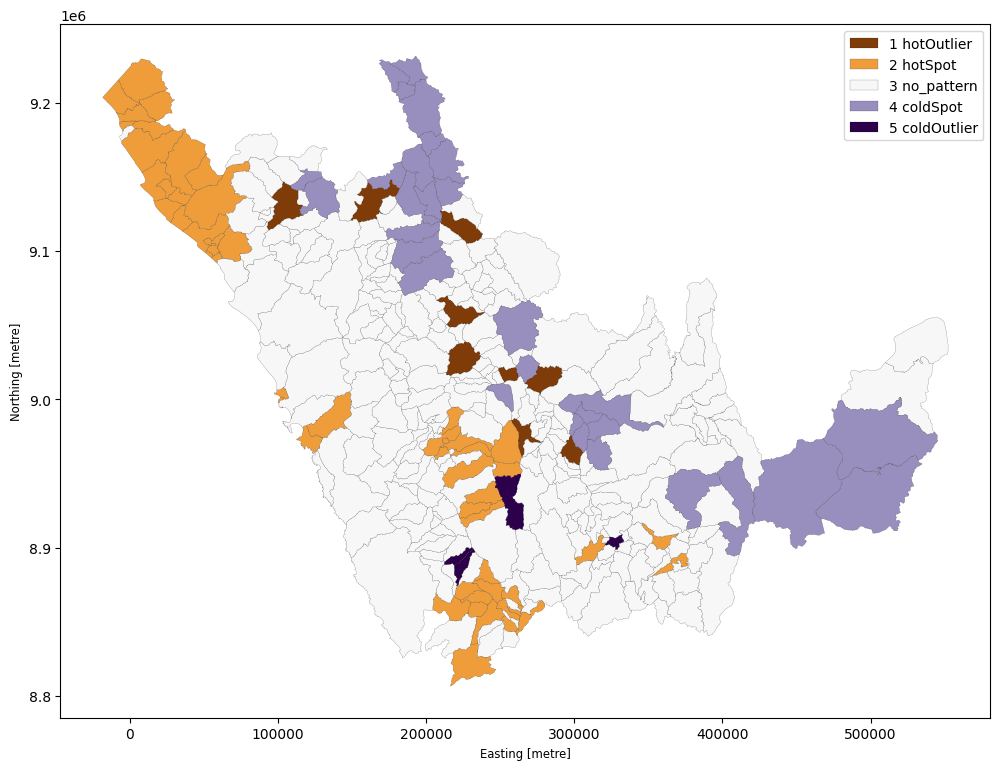

In [30]:
peru_selected.plot(
    column='HS_lisa_rook',
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor='k',
    legend=True,
    figsize=(12, 12)
)

#### I.1.B. Queen

* The key idea: A focal polygon considers another polygon a neighbor if they share a common edge or a vertex (at least one point).
* The input: A GeoDataFrame (GDF) containing polygon geometries (e.g., states, counties, census tracts). Each row represents a spatial unit that can serve as a focal observation.
* The process: For each polygon (focal unit), the algorithm checks all other polygons to determine whether their boundaries intersect at any point or along a line segment.
* The output: A graph built from a binary adjacency matrix where each node represents a polygon (focal unit). An edge exists between two nodes only if they share a point or boundary segment. The corresponding adjacency matrix is binary. Isolates are possible.

Let's see what we get:

**a. adjacency matrix**

In [31]:
queen = Graph.build_contiguity(peru_selected, rook=False)

# applying our procedure:

queen_Matrix=toWideMatrix(queen)
queen_Matrix

weight                                                          \
neighbor 021405 021404 021402 021410 021408 021409 021407 020506 020502   
focal                                                                     
021405      0.0    0.0    1.0    1.0    0.0    1.0    0.0    0.0    0.0   
021404      0.0    0.0    1.0    0.0    1.0    0.0    0.0    0.0    0.0   
021402      1.0    1.0    0.0    1.0    1.0    0.0    0.0    0.0    0.0   
021410      1.0    0.0    1.0    0.0    1.0    0.0    0.0    0.0    0.0   
021408      0.0    1.0    1.0    1.0    0.0    0.0    1.0    0.0    0.0   
...         ...    ...    ...    ...    ...    ...    ...    ...    ...   
100705      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
100608      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
100607      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
100609      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
100610      0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

                 ...                                                          \
neighbor 021406  ... 130304 130402 130305 100704 100113 100705 100608 100607   
focal            ...                                                           
021405      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
021404      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
021402      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
021410      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
021408      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
...         ...  ...    ...    ...    ...    ...    ...    ...    ...    ...   
100705      0.0  ...    0.0    0.0    0.0    1.0    0.0    0.0    0.0    0.0   
100608      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
100607      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   
100609      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    1.0    0.0   
100610      0.0  ...    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   

                        
neighbor 100609 100610  
focal                   
021405      0.0    0.0  
021404      0.0    0.0  
021402      0.0    0.0  
021410      0.0    0.0  
021408      0.0    0.0  
...         ...    ...  
100705      0.0    0.0  
100608      1.0    0.0  
100607      0.0    0.0  
100609      0.0    1.0  
100610      1.0    0.0  

[333 rows x 333 columns]

Comprobando los distritos aislados:

In [32]:
queen = queen.transform("r")
len(queen.isolates)

0

Calculo de LISA:

In [33]:
lisa_queen = esda.Moran_Local(
    peru_selected['Educ_sec_comp2019_pct'],
    queen
)

In [34]:
peru_selected['HS_lisa_queen'] = lisa_queen.get_cluster_labels(crit_value=0.05)

In [35]:
peru_selected['HS_lisa_queen'].value_counts()

,count
HS_lisa_queen,
Insignificant,234
High-High,57
Low-Low,29
High-Low,9
Low-High,4


Cambiando las etiquetas:

In [36]:
oldLabels = ['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High']

newLabels = [
    '3 no_pattern',
    '4 coldSpot',
    '2 hotSpot',
    '1 hotOutlier',
    '5 coldOutlier'
]

labels = dict(zip(oldLabels, newLabels))

peru_selected.replace({'HS_lisa_queen': labels}, inplace=True)

In [37]:
peru_selected['HS_lisa_queen'].value_counts().sort_index()

,count
HS_lisa_queen,
1 hotOutlier,9
2 hotSpot,57
3 no_pattern,234
4 coldSpot,29
5 coldOutlier,4


Creando el mapa.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

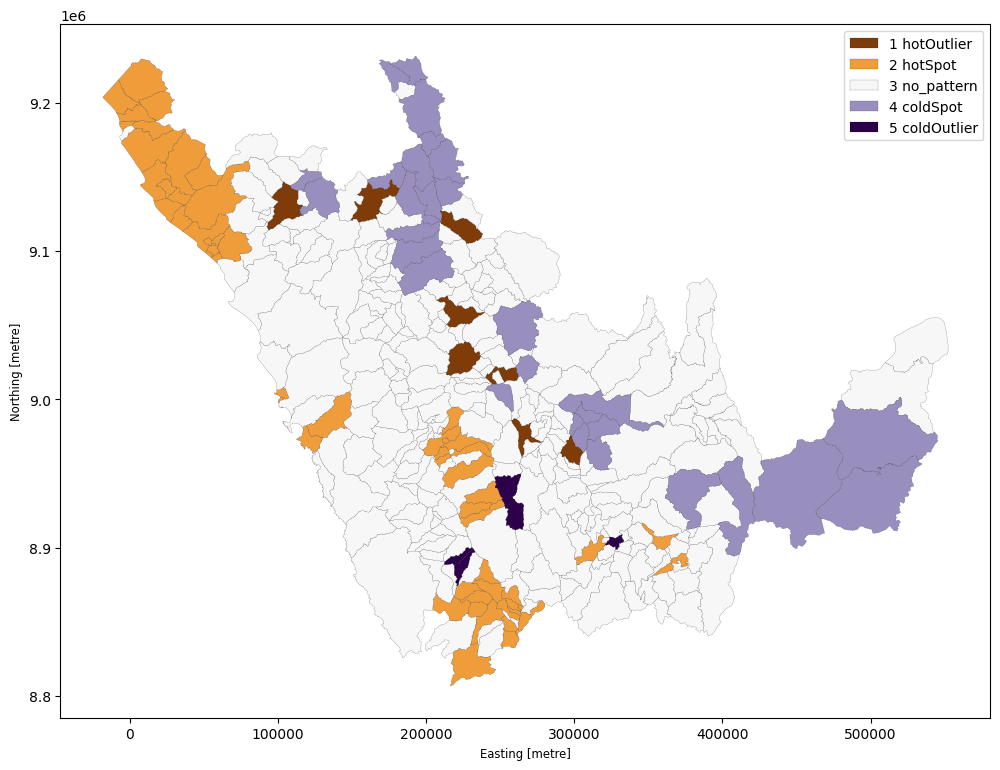

In [38]:
peru_selected.plot(
    column='HS_lisa_queen',
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor='k',
    legend=True,
    figsize=(12, 12)
)

### I.2 Binary Proximity


#### I.2.A. Nearest Neighbors

* The key idea: A focal polygon considers another polygon a neighbor if that second polygon is among the K closest polygons to the focal polygon, where “closeness” is measured by the distance between their geometric centroids (or any other user-supplied distance metric).  
* The input: A GeoDataFrame (GDF) containing polygon geometries. Each row represents a spatial unit that can serve as a focal observation.  
* The process: For each polygon (focal unit), the algorithm (1) computes the distance between its centroid and every other centroid, (2) ranks these distances, and (3) flags the K smallest distances as neighbors. Ties can be broken by random selection, ID order, or by including all tied candidates.  
* The output: A graph built from a binary adjacency matrix where each node represents a polygon (focal unit). An edge exists between two nodes whenever one polygon is among the K nearest neighbors of the other. The corresponding adjacency matrix is binary and, by construction, typically asymmetric unless a symmetric constraint is explicitly enforced. No isolates in output.

If assume K is 3:


In [39]:
knn3 = Graph.build_knn(peru_selected.representative_point(), k=3)

Estandarizando:

In [40]:
knn3 = knn3.transform("r")

¿Hay distritos aislados?

In [41]:
len(knn3.isolates)

0

Calculando los indicadores LISA:

In [42]:
lisa_knn3 = esda.Moran_Local(
    peru_selected['Educ_sec_comp2019_pct'],
    knn3
)

Obteniendo y contando las categorías.

In [43]:
peru_selected['HS_lisa_knn3'] = lisa_knn3.get_cluster_labels(crit_value=0.05)

In [44]:
peru_selected['HS_lisa_knn3'].value_counts()

,count
HS_lisa_knn3,
Insignificant,235
High-High,56
Low-Low,34
High-Low,6
Low-High,2


Cambiando las etiquetas:

In [45]:
oldLabels = ['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High']

newLabels = [
    '3 no_pattern',
    '4 coldSpot',
    '2 hotSpot',
    '1 hotOutlier',
    '5 coldOutlier'
]

labels = dict(zip(oldLabels, newLabels))

peru_selected.replace({'HS_lisa_knn3': labels}, inplace=True)

Verificando que las categorías tienen el nombre correcto.

In [46]:
peru_selected['HS_lisa_knn3'].value_counts().sort_index()

,count
HS_lisa_knn3,
1 hotOutlier,6
2 hotSpot,56
3 no_pattern,235
4 coldSpot,34
5 coldOutlier,2


TERCER MAPA

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

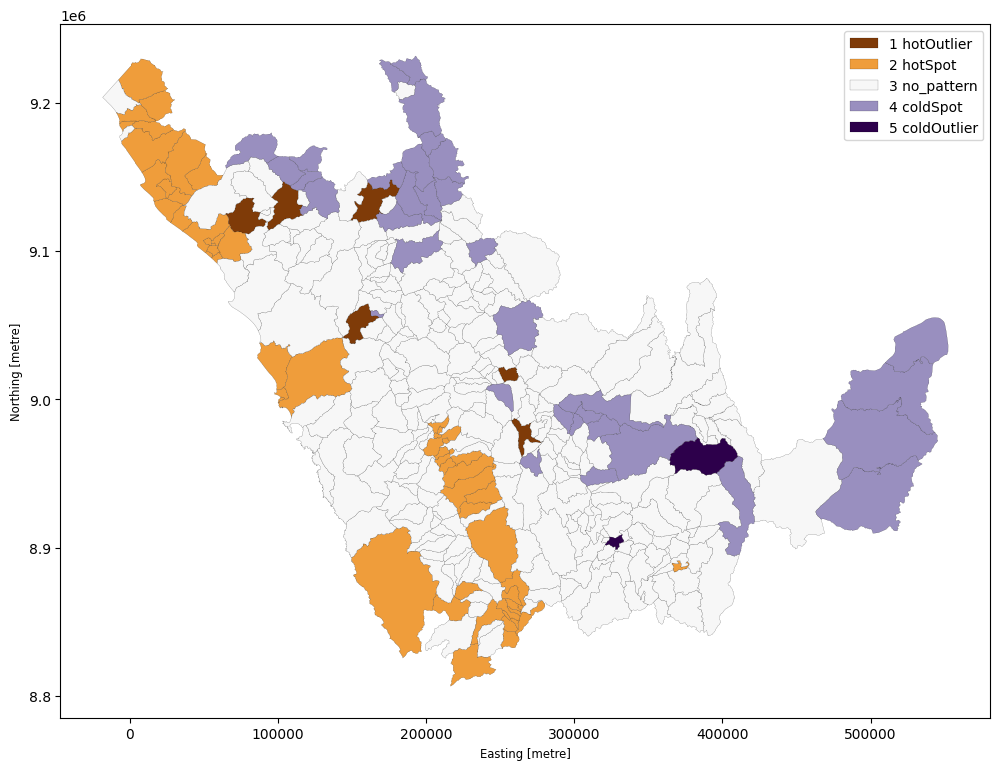

In [47]:
peru_selected.plot(
    column='HS_lisa_knn3',
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor='k',
    legend=True,
    figsize=(12, 12)
)

#### I.2.B Within zone of influence


* The key idea: A focal polygon considers another polygon a neighbor if the distance between them (usually centroid-to-centroid , or a pair of representative point) lies within a user-defined band.
* The input: A GeoDataFrame (GDF) containing polygon geometries for which a representative point is supplied. Each row represents a spatial unit that can serve as a focal observation, plus (optionally) an attribute column to use as a weight or ID.  
* The process: For each polygon (focal unit) the algorithm computes the distance to every other polygon and flags those whose distance falls inside the specified band.
* The output: A binary spatial graph (or adjacency structure) where each node represents a polygon. An edge exists between two nodes only if their mutual distance sits inside the chosen band. The corresponding adjacency matrix is binary and symmetric by construction. Isolates are possible.

Let's assume a 50 km distance band:

Voy a observar que distancia puede ser adecuada para asumir:

In [48]:
import numpy as np
from scipy.spatial.distance import cdist

points = peru_selected.representative_point()

coords = np.column_stack((points.x, points.y))

dist_matrix = cdist(coords, coords)
np.fill_diagonal(dist_matrix, np.inf)

nearest_distances = dist_matrix.min(axis=1)

pd.Series(nearest_distances).describe()

,0
count,333.000000
mean,11048.192198
std,5941.585713
min,3263.854771
25%,7164.652996
50%,9956.854366
75%,13388.250680
max,42817.986605


La distancia de 50km hace que todos los distritos tengan vecinos. Creo el graph(relacion enttre distritos y sus vecinos).

In [49]:
band50k = Graph.build_distance_band(
    points,
    threshold=50000
)

In [50]:
band50k = band50k.transform("r")

In [ ]:
len(band50k.isolates)

0

Calculo de indicadores LISA:

In [51]:
lisa_band50k = esda.Moran_Local(
    peru_selected['Educ_sec_comp2019_pct'],
    band50k
)

In [52]:
peru_selected['HS_lisa_band50k'] = lisa_band50k.get_cluster_labels(crit_value=0.05)

In [53]:
peru_selected['HS_lisa_band50k'].value_counts()

,count
HS_lisa_band50k,
Insignificant,125
Low-Low,89
High-High,74
High-Low,26
Low-High,19


Personalizando las etiquetas.

In [54]:
oldLabels = ['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High']

newLabels = [
    '3 no_pattern',
    '4 coldSpot',
    '2 hotSpot',
    '1 hotOutlier',
    '5 coldOutlier'
]

labels = dict(zip(oldLabels, newLabels))

peru_selected.replace({'HS_lisa_band50k': labels}, inplace=True)

CUARTO MAPA


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

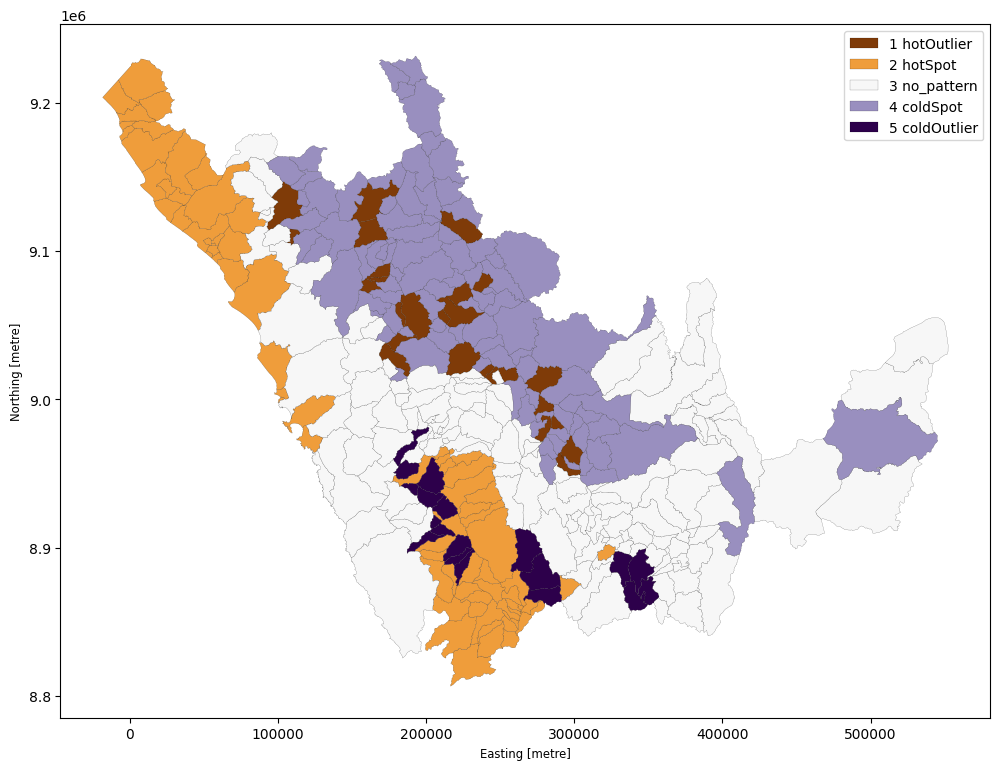

In [55]:
peru_selected.plot(
    column='HS_lisa_band50k',
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor='k',
    legend=True,
    figsize=(12, 12)
)

los cuatro mapas LISA: Rook, Queen, KNN y Distance Band.